#Setup

In [1]:
import os, time, random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for g in gpus:
        tf.config.experimental.set_memory_growth(g, True)


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE

try:
    tf.config.optimizer.set_jit(True)
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy("mixed_float16")
    print("XLA: ON | Mixed precision:", mixed_precision.global_policy())
except Exception as e:
    print("Perf options not fully enabled:", e)

TensorFlow: 2.19.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
XLA: ON | Mixed precision: <DTypePolicy "mixed_float16">


# Install + Import TFDS

In [2]:
!pip -q install tensorflow-datasets
import tensorflow_datasets as tfds

# Load Oxford-IIIT Pet Dataset

In [3]:
(ds_train_raw, ds_test_raw), info = tfds.load(
    "oxford_iiit_pet",
    split=["train", "test"],
    with_info=True,
    as_supervised=False
)

print("Train samples:", info.splits["train"].num_examples)
print("Test samples:", info.splits["test"].num_examples)

Train samples: 3680
Test samples: 3669


# Config

In [4]:
IMG_H, IMG_W = 96, 96

BATCH_SIZE = 32
EPOCHS = 15

TRAIN_CACHE_PATH = "/content/pets_train_cache"
VAL_CACHE_PATH = "/content/pets_val_cache"

# Preprocess + Fast Augmentation

In [5]:
def preprocess(example):
  img = example["image"]
  mask = example["segmentation_mask"]

  img = tf.image.resize(img, (IMG_H, IMG_W), method="bilinear")
  mask = tf.image.resize(mask,(IMG_H, IMG_W), method="nearest")

  img = tf.cast(img, tf.float32) / 255.0

  mask = tf.cast(mask == 1, tf.float32)
  mask = tf.expand_dims(tf.squeeze(mask, axis=-1), axis=-1)

  return img, mask

def augment_fast(img, mask):
  if tf.random.uniform(())> 0.5:
    img = tf.image.flip_left_right(img)
    mask = tf.image.flip_left_right(mask)
  return img, mask

# Build Fast tf.data Pipelines

In [6]:
ds_train = (ds_train_raw
            .shuffle(4000, seed=SEED, reshuffle_each_iteration=True)
            .map(preprocess, num_parallel_calls=AUTOTUNE)
            .map(augment_fast, num_parallel_calls=AUTOTUNE)
            .cache(TRAIN_CACHE_PATH)
            .batch(BATCH_SIZE, drop_remainder=True)
            .prefetch(AUTOTUNE))
ds_val = (ds_test_raw
          .map(preprocess, num_parallel_calls=AUTOTUNE)
          .cache(VAL_CACHE_PATH)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

print("Train batches:", tf.data.experimental.cardinality(ds_train).numpy())
print("Val batches  :", tf.data.experimental.cardinality(ds_val).numpy())

Train batches: 115
Val batches  : 115


# Pipeline Benchmark

In [7]:
def bench(ds, n=50):
  t0 = time.time()
  for _ in ds.take(n):
    pass
  t1 = time.time()
  print(f"{n} batches time (sec):", round(t1 - t0, 3))
  print("Avg sec/batch:", round ((t1 - t0)/n, 3))

print("Benchmark run #1 (builds/warms cache):")
bench(ds_train, n=50)

print("\nBenchmark run #2 (should be faster):")
bench(ds_train, n=50)

Benchmark run #1 (builds/warms cache):
50 batches time (sec): 22.538
Avg sec/batch: 0.451

Benchmark run #2 (should be faster):
50 batches time (sec): 10.34
Avg sec/batch: 0.207


# Visualize a Batch

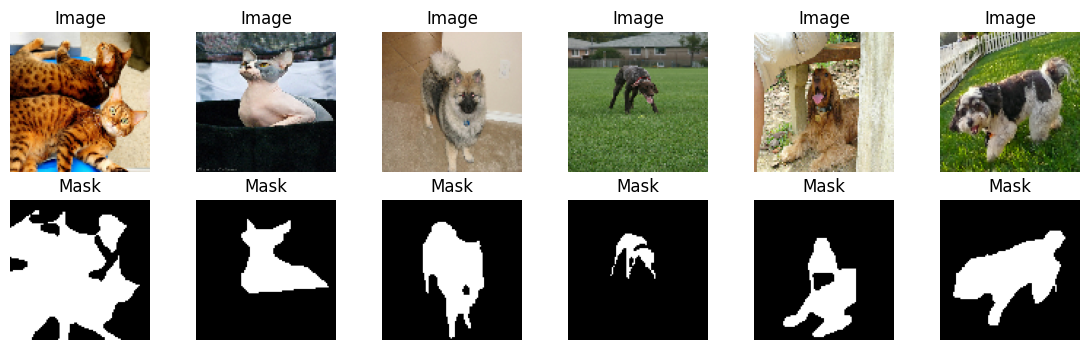

In [8]:
def show_batch(ds, n=6):
  for imgs, masks in ds.take(1):
    imgs = imgs.numpy()
    masks = masks.numpy()

  n = min(n, imgs.shape[0])
  plt.figure(figsize=(14, 4))
  for i in range(n):
    plt.subplot(2, n, i+1)
    plt.imshow(imgs[i])
    plt.axis("off")
    plt.title("Image")

    plt.subplot(2, n, n+i+1)
    plt.imshow(masks[i].squeeze(), cmap="gray")
    plt.axis("off")
    plt.title("Mask")
  plt.show()

show_batch(ds_train, n=6)

# Metrics + Loss (Dice + IoU + BCE+Dice)

In [9]:
@tf.function
def iou_score(y_true, y_pred, thr=0.5, eps=1e-7):
  y_true = tf.cast(y_true > 0.5, tf.float32)
  y_pred = tf.cast(y_pred > thr, tf.float32)
  inter = tf.reduce_sum(y_true * y_pred, axis=[1,2,3])
  union = tf.reduce_sum(y_true + y_pred, axis=[1,2,3]) - inter
  return tf.reduce_mean((inter + eps) / (union + eps))

@tf.function
def dice_coef(y_true, y_pred, eps=1e-7):
  y_true = tf.cast(y_true, tf.float32)
  y_pred = tf.cast(y_pred, tf.float32)
  inter = tf.reduce_sum(y_true * y_pred, axis=[1,2,3])
  denom = tf.reduce_sum(y_true + y_pred, axis=[1,2,3])
  return tf.reduce_mean((2.0 * inter + eps) / (denom + eps))

@tf.function
def dice_loss(y_true, y_pred):
  return 1.0 - dice_coef(y_true, y_pred)

@tf.function
def bce_dice_loss(y_true, y_pred):
  bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
  return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)

# U-Net Model

In [10]:
from tensorflow.keras import layers, Model

def conv_block(x, filters, drop=0.0):
  x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
  x = layers.Activation("relu")(x)
  if drop > 0:
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.Activation("relu")(x)
    return x

def build_unet_fast(input_shape=(IMG_H, IMG_W, 3), base=16):
  inputs = layers.Input(shape=input_shape)

  x = layers.Lambda(lambda t: tf.cast(t, tf.float32))(inputs)

  c1 = conv_block(x, base, 0.05);  p1 = layers.MaxPooling2D()(c1)
  c2 = conv_block(p1, base*2,0.05); p2 = layers.MaxPooling2D()(c2)
  c3 = conv_block(p2, base*4, 0.10);  p3 = layers.MaxPooling2D()(c3)
  c4 = conv_block(p3, base*8, 0.10); p4 = layers.MaxPooling2D()(c4)

  c5 = conv_block(p4, base*16, 0.15)

  u6 = layers.Conv2DTranspose(base*8, 2, strides=2, padding="same")(c5)
  u6 = layers.Concatenate()([u6, c4])
  c6 = conv_block(u6, base*8, 0.10)

  u7 = layers.Conv2DTranspose(base*4, 2, strides=2, padding="same")(c6)
  u7 = layers.Concatenate()([u7, c3])
  c7 = conv_block(u7, base*4, 0.10)

  u8 = layers.Conv2DTranspose(base*2, 2, strides=2, padding="same")(c7)
  u8 = layers.Concatenate()([u8, c2])
  c8 = conv_block(u8, base*2, 0.05)

  u9 = layers.Conv2DTranspose(base, 2, strides=2, padding="same")(c8)
  u9 = layers.Concatenate()([u9, c1])
  c9 = conv_block(u9, base, 0.05)

  outputs = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32")(c9)

  return Model(inputs, outputs)

model = build_unet_fast(base=16)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 96, 96, 3) │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 96, 96,    │        448 │ lambda[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 96, 96,    │          0 │ conv2d[0][0]      │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 96, 96,    │      2,320 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 96, 96,    │          0 │ conv2d_1[0][0]    │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 48, 48,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 48, 48,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 48, 48,    │          0 │ conv2d_2[0][0]    │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 48, 48,    │      9,248 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 48, 48,    │          0 │ conv2d_3[0][0]    │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 24, 24,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 24, 24,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 24, 24,    │          0 │ conv2d_4[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 24, 24,    │     36,928 │ activation_4[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 24, 24,    │          0 │ conv2d_5[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 12, 12,    │          0 │ activation_5[0][… │
│ (MaxPooling2D)      │ 64)               │            │                 

 Total params: 1,941,105 (7.40 MB)

 Trainable params: 1,941,105 (7.40 MB)

 Non-trainable params: 0 (0.00 B)

# Compile

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=bce_dice_loss,
    metrics=[dice_coef, iou_score]
)

# Train

In [12]:
ckpt_path = "unet_pets_best.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]


history = model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/15
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - dice_coef: 0.4515 - iou_score: 0.3624 - loss: 1.1266
Epoch 1: val_loss improved from inf to 0.87378, saving model to unet_pets_best.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 92s 331ms/step - dice_coef: 0.4526 - iou_score: 0.3636 - loss: 1.1244 - val_dice_coef: 0.5798 - val_iou_score: 0.5209 - val_loss: 0.8738 - learning_rate: 0.0010
Epoch 2/15
113/115 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - dice_coef: 0.6256 - iou_score: 0.5553 - loss: 0.7748
Epoch 2: val_loss improved from 0.87378 to 0.69745, saving model to unet_pets_best.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 62s 38ms/step - dice_coef: 0.6262 - iou_score: 0.5559 - loss: 0.7737 - val_dice_coef: 0.6375 - val_iou_score: 0.6057 - val_loss: 0.6974 - learning_rate: 0.0010
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - dice_coef: 0.6932 - iou_score: 0.6264 - loss: 0.6405
Epoch 3: val_loss improved from 0.69745 to 0.59087, saving model to unet_pets_best.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 5s 4

# Plot Training Curves

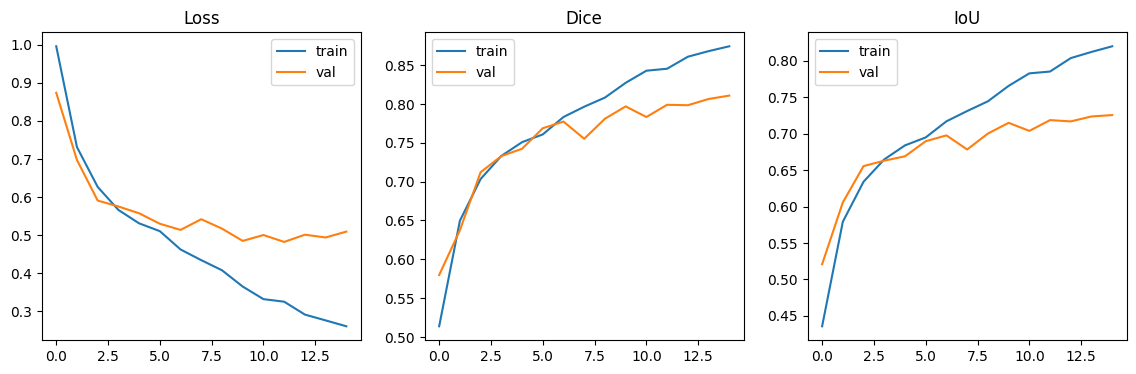

In [14]:
def plot_history(hist):
  plt.figure(figsize=(14,4))

  plt.subplot(1,3,1)
  plt.plot(hist.history["loss"], label="train")
  plt.plot(hist.history["val_loss"], label="val")
  plt.title("Loss"); plt.legend()

  plt.subplot(1,3,2)
  plt.plot(hist.history["dice_coef"], label="train")
  plt.plot(hist.history["val_dice_coef"], label="val")
  plt.title("Dice"); plt.legend()

  plt.subplot(1,3,3)
  plt.plot(hist.history["iou_score"], label="train")
  plt.plot(hist.history["val_iou_score"], label="val")
  plt.title("IoU"); plt.legend()

  plt.show()

plot_history(history)


# Predictions Visualization

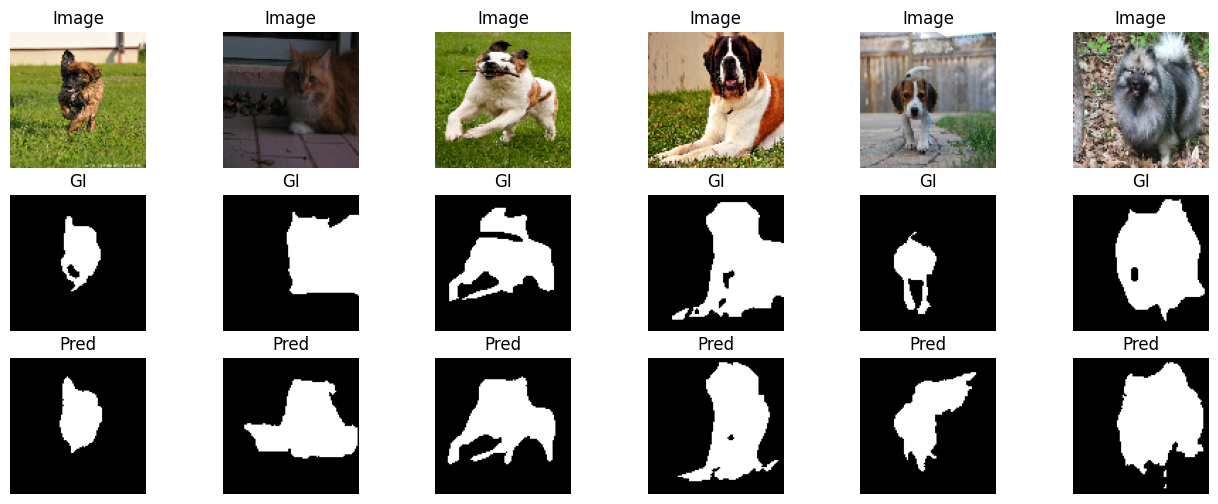

In [15]:
def visualize_predictions(ds, n=6, thr=0.5):
  for imgs, masks in ds.take(1):
    preds = model.predict(imgs, verbose=0)
    imgs = imgs.numpy()
    masks = masks.numpy()
    preds_bin = (preds > thr).astype(np.uint8)

  n = min(n, imgs.shape[0])
  plt.figure(figsize=(16, 6))
  for i in range(n):
    plt.subplot(3, n, i+1)
    plt.imshow(imgs[i])
    plt.axis("off")
    plt.title("Image")

    plt.subplot(3, n, n+i+1)
    plt.imshow(masks[i].squeeze(), cmap="gray")
    plt.axis("off")
    plt.title("GI")

    plt.subplot(3, n, 2*n+i+1)
    plt.imshow(preds_bin[i].squeeze(), cmap="gray")
    plt.axis("off")
    plt.title("Pred")
  plt.show()

visualize_predictions(ds_val, n=6)

# Evaluate

In [16]:
results = model.evaluate(ds_val, verbose=1)
print("Val results:", dict(zip(model.metrics_names, results)))

115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - dice_coef: 0.7996 - iou_score: 0.7201 - loss: 0.4745
Val results: {'loss': 0.482233464717865, 'compile_metrics': 0.7990275025367737}


# Save Model

In [17]:
model.save("/content/unet_pets_final.keras")
print("Saved model to /content/unet_pets_final.keras")

Saved model to /content/unet_pets_final.keras
